# M5 Retail Demand Forecasting — Notebook 5: Final Holdout Evaluation

**This notebook produces the project's one unbiased accuracy number.**

The three validation folds (Feb–Apr 2016) were used for many decisions: feature selection, tuning, the `item_id` question and the choice between LightGBM, Chronos-2 and TFT. Each decision lets some information about those folds seep into the final model, so their scores are slightly optimistic. The **final holdout** is different: days `d_1914` to `d_1941` (2016-04-25 to 2016-05-22) were never loaded in any earlier notebook and no decision was based on them. It is used **once**.

| | |
|---|---|
| **Inputs** | `m5_sample_long.parquet`, `lgbm_final_h28.txt`, `lgbm_config_h28.json`, `preds_lgbm_h28.parquet`, `m5_series_stats.parquet`, and the Kaggle files `sales_train_evaluation.csv`, `calendar.csv`, `sell_prices.csv` |
| **Outputs** | `m5_sample_long_ext.parquet`, `preds_holdout_h28.parquet`, `holdout_runs.jsonl` |

**Rules fixed in advance**
1. **The model is fixed:** `lgbm_final_h28.txt` from Notebook 3. Its SHA-256 fingerprint is recorded so it can be shown that the model predates the holdout evaluation.
2. **The benchmark is fixed:** the 28-day moving average (the strongest baseline on the folds).
3. **No tuning, no feature change, no retraining.** Whatever the result is, it is reported.
4. **Every run is logged** to an append-only file (`holdout_runs.jsonl`). The first run is the official result; later runs are logged as re-runs.
5. The result is reported with a **bootstrap confidence interval**, not as a single number.

Note: `sales_train_evaluation.csv` is required (the validation file does not contain days 1914–1941).

---
## 1. Setup and model fingerprint

A cryptographic hash identifies a file exactly: if the model file changes by a single byte the hash changes. Recording it allows us to state that the evaluated model is the one trained before the holdout was used.

In [1]:
import json, time, hashlib, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import lightgbm as lgb

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

SEED = 42
H = 28
MIN_CONTEXT = 56          # eligibility rule of Notebook 4 (at least 56 available days at the origin)
FULL_M5_SERIES = 30490    # total item-store series in M5 (used to compute the share)

def find_file(name):
    for root in [Path(".")] + ([Path("..")] if not Path("data").exists() else []) + [Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            hits = list(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found.")

LONG_PATH  = find_file("m5_sample_long.parquet")
CFG_PATH   = find_file("feature_config.json")
STATS_PATH = find_file("m5_series_stats.parquet")
MODEL_PATH = find_file("lgbm_final_h28.txt")
MCFG_PATH  = find_file("lgbm_config_h28.json")
PRED_PATH  = find_file("preds_lgbm_h28.parquet")
SALES_PATH = find_file("sales_train_evaluation.csv")
CAL_PATH   = find_file("calendar.csv")
PRICE_PATH = find_file("sell_prices.csv")
OUT = Path("/kaggle/working/processed") if Path("/kaggle/working").exists() else (Path("../data/processed") if (not Path("data").exists() and Path("../data").exists()) else Path("data/processed"))
OUT.mkdir(parents=True, exist_ok=True)

def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

MODEL_SHA = sha256(MODEL_PATH); MCFG_SHA = sha256(MCFG_PATH)
print("Model file :", MODEL_PATH.name, "| sha256:", MODEL_SHA[:16], "...")
print("Config file:", MCFG_PATH.name, "| sha256:", MCFG_SHA[:16], "...")
print("Output     :", OUT)

Model file : lgbm_final_h28.txt | sha256: bdad92a08cba326a ...
Config file: lgbm_config_h28.json | sha256: a3afa455397d7e30 ...
Output     : /kaggle/working/processed


---
## 2. Adding the 28 holdout days

The long table from Notebook 1 ends on 2016-04-24 (the forecast origin). For the same 999 series we append days `d_1914`…`d_1941` from `sales_train_evaluation.csv`, with the calendar (events, SNAP) and weekly prices.

- Series are matched on `(item_id, store_id)`; the `id` suffix differs between the validation and evaluation files.
- The price join is checked with `assert` on the row count.
- `is_available` is recomputed with the same rule as before (from the first price onward) and verified to be unchanged for the old rows.

**Can the holdout actuals leak into the features?** Every sales-based feature is shifted by at least 28 days, so a holdout row's features only use data from before 2016-04-25. Section 3 proves this by replacing the holdout sales with random numbers and checking that the features do not change.

In [2]:
long = pd.read_parquet(LONG_PATH)
long["date"] = pd.to_datetime(long["date"])
ORIGIN = long["date"].max()
cfg = json.loads(CFG_PATH.read_text())
assert ORIGIN == pd.Timestamp(cfg["folds"][0]["valid_end"]), "Last day of the data does not match valid_end of fold 1"
print("Forecast origin (last training day):", ORIGIN.date())

ids_df = long.drop_duplicates("id")[["id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "vol_tier"]]
STATE = ids_df["state_id"].unique(); assert len(STATE) == 1, "Exactly one state expected"
STATE = STATE[0]

HOLD_D = [f"d_{i}" for i in range(1914, 1942)]
head = pd.read_csv(SALES_PATH, nrows=0).columns
assert all(d in head for d in HOLD_D), "sales_train_evaluation.csv is required (it contains d_1914..d_1941)"

sal = pd.read_csv(SALES_PATH, usecols=["item_id", "store_id"] + HOLD_D, dtype={d: "int16" for d in HOLD_D})
sal = sal.merge(ids_df[["id", "item_id", "store_id"]], on=["item_id", "store_id"], how="inner", validate="one_to_one")
assert len(sal) == len(ids_df), "Some series are missing in the evaluation file"
hold = sal.melt(id_vars=["id", "item_id", "store_id"], value_vars=HOLD_D, var_name="d", value_name="sales")

cal = pd.read_csv(CAL_PATH, parse_dates=["date"])
cal_h = cal.loc[cal["d"].isin(HOLD_D), ["d", "date", "wm_yr_wk", "weekday", "wday", "month", "year",
                                         "event_name_1", "event_type_1", f"snap_{STATE}"]].rename(columns={f"snap_{STATE}": "snap"})
hold = hold.merge(cal_h, on="d", how="left")
assert hold["date"].notna().all()
assert hold["date"].min() == ORIGIN + pd.Timedelta(days=1) and hold["date"].max() == ORIGIN + pd.Timedelta(days=H)
HOLD_START, HOLD_END = hold["date"].min(), hold["date"].max()
print("Holdout window:", HOLD_START.date(), "->", HOLD_END.date())

hold = hold.merge(ids_df[["id", "dept_id", "cat_id", "state_id", "vol_tier"]], on="id", how="left", validate="many_to_one")

prices = pd.read_csv(PRICE_PATH)
prices = prices[prices["store_id"].isin(ids_df["store_id"].unique()) & prices["item_id"].isin(ids_df["item_id"].unique())]
n0 = len(hold)
hold = hold.merge(prices, on=["store_id", "item_id", "wm_yr_wk"], how="left", validate="many_to_one")
assert len(hold) == n0
print(f"Holdout price match rate: {hold['sell_price'].notna().mean():.1%}")

keep = [c for c in long.columns if c != "is_available"]
ext = pd.concat([long[keep + ["is_available"]], hold[keep]], ignore_index=True)
first_price = ext.loc[ext["sell_price"].notna()].groupby("id")["date"].min()
ext["is_available"] = ext["date"] >= ext["id"].map(first_price)
mismatch = int((ext["is_available"].iloc[:len(long)].to_numpy() != long["is_available"].to_numpy()).sum())
assert mismatch == 0, f"is_available changed for old rows ({mismatch})"
ext = ext.sort_values(["id", "date"]).reset_index(drop=True)
print("Extended table:", ext.shape, "| series:", ext["id"].nunique(), "| days:", ext["date"].nunique())
ext.to_parquet(OUT / "m5_sample_long_ext.parquet", index=False)

Forecast origin (last training day): 2016-04-24
Holdout window: 2016-04-25 -> 2016-05-22
Holdout price match rate: 100.0%
Extended table: (1939059, 19) | series: 999 | days: 1941


---
## 3. Features and leakage proof

The next cell is a verbatim copy of `build_features()` from Notebook 2, so the holdout features are built exactly as the training features were.

**Leakage proof.** The holdout sales are replaced with random numbers and the features are rebuilt. If any feature saw the holdout actuals it would change; passing means the actuals cannot reach the model through the features.

In [3]:
CAL_CAP = 14   # event distances are capped at 14 days

def _to_wide(values, ids, dates):
    """Long (id-major) 1D values -> matrix (dates x ids)."""
    arr = np.asarray(values, dtype="float32").reshape(len(ids), len(dates)).T
    return pd.DataFrame(arr, index=dates, columns=ids)

def _to_flat(W):
    """Matrix (dates x ids) -> long (id-major) 1D array."""
    return W.to_numpy(dtype="float32").T.ravel()


def build_features(long, h, lag_weeks=4, windows=(7, 14, 28, 56)):
    """
    long : long table from the EDA notebook (id, date, sales, is_available, sell_price, snap, events ...)
    h    : forecast horizon in days. All sales-based features are at least h days old.
    return: (features_df, groups_dict)
    """
    # ---------- 0) Sort the panel and verify alignment ----------
    long = long.sort_values(["id", "date"]).reset_index(drop=True)
    ids   = long["id"].drop_duplicates().tolist()
    dates = pd.DatetimeIndex(np.sort(long["date"].unique()))
    n_ids, n_dates = len(ids), len(dates)
    assert len(long) == n_ids * n_dates, "Incomplete panel: some series are missing days"
    assert (dates[-1] - dates[0]).days == n_dates - 1, "Dates are not daily-continuous"
    assert (long["date"].to_numpy() == np.tile(dates.to_numpy(), n_ids)).all(), "Date alignment is wrong"
    assert (long["id"].to_numpy() == np.repeat(np.array(ids, dtype=object), n_dates)).all(), "ID alignment is wrong"

    F, G = {}, {}

    # ---------- 1) Sales matrix: unavailable = NaN (not zero!) ----------
    S  = _to_wide(long["sales"].where(long["is_available"]), ids, dates)
    Sh = S.shift(h)                       # <-- the key line: data that is at least h days old

    # ---------- 2) Lags (multiples of 7 => same weekday) ----------
    G["lags"] = []
    for k in range(lag_weeks):
        L = h + 7 * k
        F[f"lag_{L}"] = _to_flat(S.shift(L))
        G["lags"].append(f"lag_{L}")

    # ---------- 3) Rolling mean/std (shift FIRST, then roll) ----------
    G["rolling"] = []
    for w in windows:
        F[f"roll_mean_{w}"] = _to_flat(Sh.rolling(w, min_periods=1).mean())
        F[f"roll_std_{w}"]  = _to_flat(Sh.rolling(w, min_periods=2).std())
        G["rolling"] += [f"roll_mean_{w}", f"roll_std_{w}"]

    # ---------- 4) Derived ----------
    lag_cols = G["lags"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        F["same_weekday_mean"] = np.nanmean(np.vstack([F[c] for c in lag_cols]), axis=0)
    F["trend_ratio"] = F["roll_mean_14"] / (F["roll_mean_56"] + 0.01)
    G["rolling"] += ["same_weekday_mean", "trend_ratio"]

    # ---------- 5) Intermittency ----------
    Z  = (S == 0).astype("float32").where(S.notna())     # 1 = zero-sales day, 0 = sale occurred, NaN = unavailable
    Zh = Z.shift(h)
    F["zero_share_28"]    = _to_flat(Zh.rolling(28, min_periods=1).mean())
    F["zero_share_56"]    = _to_flat(Zh.rolling(56, min_periods=1).mean())
    F["nonzero_mean_56"]  = _to_flat(Sh.where(Sh > 0).rolling(56, min_periods=1).mean())   # average size of a sale when one occurs
    arr  = Sh.to_numpy()
    pos  = np.arange(n_dates)[:, None]
    last = pd.DataFrame(np.where(arr > 0, pos, np.nan)).ffill().to_numpy()   # position of the last sale
    F["days_since_last_sale"] = (pos - last).T.ravel().astype("float32")
    G["intermittency"] = ["zero_share_28", "zero_share_56", "nonzero_mean_56", "days_since_last_sale"]

    # ---------- 6) Calendar (known in the future => no shift needed) ----------
    d = long["date"]
    F["dow"]         = d.dt.dayofweek.to_numpy().astype("int8")
    F["month"]       = d.dt.month.to_numpy().astype("int8")
    F["dom"]         = d.dt.day.to_numpy().astype("int8")
    F["weekofyear"]  = d.dt.isocalendar().week.to_numpy().astype("int8")
    F["is_weekend"]  = (F["dow"] >= 5).astype("int8")
    F["is_christmas"] = ((F["month"] == 12) & (F["dom"] == 25)).astype("int8")
    F["snap"]        = long["snap"].to_numpy().astype("int8")
    F["has_event"]   = long["event_name_1"].notna().to_numpy().astype("int8")

    # event distance: computed at date level (1,913 days), then tiled for every series
    ev_days = np.sort(((pd.DatetimeIndex(long.loc[long["event_name_1"].notna(), "date"].unique()) - dates[0]).days).to_numpy())
    d_days  = np.arange(n_dates)
    if len(ev_days):
        nxt_i = np.searchsorted(ev_days, d_days, side="left")
        nxt   = np.where(nxt_i < len(ev_days), ev_days[np.minimum(nxt_i, len(ev_days) - 1)] - d_days, CAL_CAP)
        prv_i = np.searchsorted(ev_days, d_days, side="right") - 1
        prv   = np.where(prv_i >= 0, d_days - ev_days[np.maximum(prv_i, 0)], CAL_CAP)
    else:
        nxt = prv = np.full(n_dates, CAL_CAP)
    F["days_to_next_event"]   = np.tile(np.minimum(nxt, CAL_CAP).astype("int8"), n_ids)
    F["days_since_last_event"] = np.tile(np.minimum(prv, CAL_CAP).astype("int8"), n_ids)
    G["calendar"] = ["dow", "month", "dom", "weekofyear", "is_weekend", "is_christmas", "snap",
                     "has_event", "event_type", "days_to_next_event", "days_since_last_event"]

    # ---------- 7) Price ----------
    P = _to_wide(long["sell_price"], ids, dates)
    F["sell_price"]         = _to_flat(P)
    F["price_change_1w"]    = _to_flat(P / P.shift(7) - 1)
    F["price_vs_past_mean"] = _to_flat(P / P.shift(h).expanding(min_periods=1).mean() - 1)
    G["price"] = ["sell_price", "price_change_1w", "price_vs_past_mean"]

    # ---------- 8) Series info ----------
    first_av = long["date"].where(long["is_available"]).groupby(long["id"]).transform("min")
    F["age_days"] = (long["date"] - first_av).dt.days.to_numpy().astype("float32")
    G["series_info"] = ["item_id", "dept_id", "cat_id", "store_id", "age_days"]

    # ---------- Assemble ----------
    out = pd.DataFrame({
        "id": long["id"], "date": long["date"],
        "sales": long["sales"].astype("float32"),
        "is_available": long["is_available"],
        "vol_tier": long["vol_tier"],                       # for error analysis only, not a feature
        "event_type": long["event_type_1"].fillna("none").astype("category"),
        "item_id": long["item_id"].astype("category"),
        "dept_id": long["dept_id"].astype("category"),
        "cat_id": long["cat_id"].astype("category"),
        "store_id": long["store_id"].astype("category"),
    })
    out = pd.concat([out, pd.DataFrame(F)], axis=1)
    return out, G


def model_rows(df, h):
    """Rows used for training/evaluation: available rows only, after removing the burn-in period where lags cannot exist yet."""
    burn_end = df["date"].min() + pd.Timedelta(days=h + 56)
    return df[df["is_available"] & (df["date"] >= burn_end)].reset_index(drop=True)

print("Functions ready")

Functions ready


In [4]:
use = ["id", "date", "sales", "is_available", "sell_price", "snap", "event_name_1", "event_type_1",
       "item_id", "dept_id", "cat_id", "store_id", "vol_tier"]
t0 = time.time()
A, G = build_features(ext[use], H)
print(f"Features built in {time.time()-t0:.0f}s | shape {A.shape}")

mcfg = json.loads(MCFG_PATH.read_text())
FEATS = mcfg["features"]
missing = [c for c in FEATS if c not in A.columns]
assert not missing, f"Model features missing from the table: {missing}"
print("Model features:", len(FEATS), "| final variant:", mcfg.get("final_variant"))

# ---- Leakage proof: replace the holdout actuals with random numbers ----
bad = ext[use].copy()
bad["sales"] = bad["sales"].astype("float32")
m = bad["date"] > ORIGIN
bad.loc[m, "sales"] = np.random.default_rng(0).integers(0, 100, int(m.sum())).astype("float32")
B, _ = build_features(bad, H)

CAT_F = {"item_id", "dept_id", "cat_id", "store_id", "event_type"}
num_feats = [c for c in FEATS if c not in CAT_F]
rows = (A["date"] > ORIGIN).to_numpy()
results = {c: bool(np.allclose(A.loc[rows, c].to_numpy(dtype=float), B.loc[rows, c].to_numpy(dtype=float), equal_nan=True)) for c in num_feats}
cat_ok = all((A.loc[rows, c].astype(str).to_numpy() == B.loc[rows, c].astype(str).to_numpy()).all() for c in FEATS if c in CAT_F)
failed = [c for c, ok in results.items() if not ok]
print(f"\nOn holdout rows {len(num_feats) - len(failed)}/{len(num_feats)} numeric features unchanged | categorical features unchanged: {cat_ok}")
assert not failed and cat_ok, f"LEAKAGE: these features changed with the holdout actuals: {failed}"
print("LEAKAGE PROOF PASS: the holdout actuals cannot reach the features")
del bad, B

Features built in 4s | shape (1939059, 42)
Model features: 37 | final variant: var_all

On holdout rows 32/32 numeric features unchanged | categorical features unchanged: True
LEAKAGE PROOF PASS: the holdout actuals cannot reach the features


---
## 4. Predictions and baselines

**Eligible rows.** As in Notebook 4, only series with at least 56 available days at the origin are used, so the baselines and the model are scored on identical rows. Results for all available rows are shown as well.

**Baselines** (all computed from data up to the origin):

| Baseline | Definition |
|---|---|
| `naive_lag28` | same weekday 28 days earlier |
| `moving_avg_28` | **pre-specified benchmark**: mean of the last 28 days |
| `same_weekday_mean` | mean of the last four same-weekday values |
| `croston_sba` | intermittent-demand method |

**Model.** The saved LightGBM booster is loaded from file. LightGBM stores the category lists of pandas categorical columns inside the model file and maps incoming data to them, so `item_id`, `store_id` and similar columns are encoded as in training even if the category order differs in the new table.

In [5]:
def croston_sba(S, alpha=0.1):
    arr = S.to_numpy(dtype="float64"); n, m = arr.shape
    z = np.full(m, np.nan); p = np.full(m, np.nan); q = np.zeros(m)
    F = np.zeros((n, m))
    for i in range(n):
        y = arr[i]; obs = ~np.isnan(y)
        q = q + obs
        dem = obs & (y > 0)
        init = dem & np.isnan(z); upd = dem & ~np.isnan(z)
        z = np.where(init, y, z);  p = np.where(init, q, p)
        z = np.where(upd, z + alpha * (y - z), z)
        p = np.where(upd, p + alpha * (q - p), p)
        q = np.where(dem, 0.0, q)
        F[i] = np.where(np.isnan(z), 0.0, (1 - alpha / 2) * z / p)
    return pd.DataFrame(F, index=S.index, columns=S.columns)

# ---- wide sales matrix (aligned with the row order of A) ----
es = ext.sort_values(["id", "date"]).reset_index(drop=True)
ids = es["id"].drop_duplicates().tolist()
dates = pd.DatetimeIndex(np.sort(es["date"].unique()))
nd = len(dates)
assert (A["id"].to_numpy()[::nd] == np.array(ids, dtype=object)).all(), "Row order is not aligned"
S = _to_wide(es["sales"].where(es["is_available"]), ids, dates)
CR = croston_sba(S, 0.1).shift(H)               # forecast for target t uses data up to (t - H)
A["croston_sba"] = _to_flat(CR)

# ---- holdout rows ----
cnt = ext[(ext["date"] <= ORIGIN) & ext["is_available"]].groupby("id").size()
ELIG = set(cnt[cnt >= MIN_CONTEXT].index)
hold_all = A[(A["date"] >= HOLD_START) & A["is_available"]].copy()
hold_all["eligible"] = hold_all["id"].isin(ELIG)
print(f"Holdout rows (available): {len(hold_all):,} | eligible: {int(hold_all['eligible'].sum()):,} "
      f"({hold_all['eligible'].mean():.2%}) | eligible series: {len(ELIG)}")

# ---- model predictions (the model is fixed; no retraining) ----
booster = lgb.Booster(model_file=str(MODEL_PATH))
hold_all["lgbm_final"] = np.clip(booster.predict(hold_all[FEATS]), 0, None)
hold_all["naive_lag28"]       = hold_all[f"lag_{H}"].fillna(0)
hold_all["moving_avg_28"]     = hold_all["roll_mean_28"].fillna(0)
hold_all["same_weekday_mean"] = hold_all["same_weekday_mean"].fillna(0)
hold_all["croston_sba"]       = hold_all["croston_sba"].fillna(0)
hold_all = hold_all.rename(columns={"sales": "y"})

stats = pd.read_parquet(STATS_PATH); stats["id"] = stats["id"].astype(str)
hold_all["demand_class"] = hold_all["id"].astype(str).map(stats.set_index("id")["demand_class"])
H_E = hold_all[hold_all["eligible"]].reset_index(drop=True)      # headline set
print("Predictions done.", "| negative preds:", int((hold_all['lgbm_final'] < 0).sum()))

Holdout rows (available): 27,972 | eligible: 27,972 (100.00%) | eligible series: 999
Predictions done. | negative preds: 0


---
## 5. Holdout result (official)

The same metrics as before: WAPE (main), MAE, bias %, MASE, and WAPE of 7-day and 28-day sums. The MASE scale comes from the training period (up to the origin).

In [6]:
MODELS = ["naive_lag28", "moving_avg_28", "same_weekday_mean", "croston_sba", "lgbm_final"]

def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.abs(y - p).sum() / y.sum()) if y.sum() > 0 else float("nan")

def blocks(df, days):
    return ((df["date"] - df["date"].min()).dt.days.to_numpy() // days)

def agg_wape(df, col, days):
    tmp = pd.DataFrame({"id": df["id"].to_numpy(), "blk": blocks(df, days), "y": df["y"].to_numpy(float), "p": df[col].to_numpy(float)})
    g = tmp.groupby(["id", "blk"])[["y", "p"]].sum()
    return float(np.abs(g["y"] - g["p"]).sum() / g["y"].sum())

_D = (S - S.shift(H)).abs().loc[:ORIGIN]
SCALE = _D.mean()

def evaluate(df, col):
    y = df["y"].to_numpy(float); p = df[col].to_numpy(float)
    sc = df["id"].map(SCALE).to_numpy(float); ok = sc > 0
    return {"WAPE": wape(y, p), "MAE": float(np.abs(y - p).mean()), "bias_%": float((p.sum() - y.sum()) / y.sum() * 100),
            "MASE": float((np.abs(y - p)[ok] / sc[ok]).mean()),
            "WAPE_7d_sum": agg_wape(df, col, 7), "WAPE_28d_sum": agg_wape(df, col, 28)}

def table(df):
    t = pd.DataFrame({m: evaluate(df, m) for m in MODELS}).T
    t["vs_MA28_%"] = (1 - t["WAPE"] / t.loc["moving_avg_28", "WAPE"]) * 100
    return t

print(f"=== HOLDOUT ({HOLD_START.date()} -> {HOLD_END.date()}) | eligible rows: {len(H_E):,} | series: {H_E['id'].nunique()} ===")
hold_tbl = table(H_E)
display(hold_tbl)

print("\nAll available rows (without the eligibility filter):")
display(table(hold_all.reset_index(drop=True)))

=== HOLDOUT (2016-04-25 -> 2016-05-22) | eligible rows: 27,972 | series: 999 ===


,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,vs_MA28_%
naive_lag28,0.9238,1.3284,-4.0300,1.1349,0.4469,0.2711,-17.0485
moving_avg_28,0.7893,1.1349,-3.9381,0.9778,0.4156,0.3141,0.0000
same_weekday_mean,0.8113,1.1667,-3.8914,1.0075,0.4054,0.3026,-2.7942
croston_sba,0.7909,1.1372,-3.8480,0.9872,0.4095,0.3004,-0.2007
lgbm_final,0.7443,1.0703,-6.8564,0.9670,0.3700,0.2629,5.6951



All available rows (without the eligibility filter):


,WAPE,MAE,bias_%,MASE,WAPE_7d_sum,WAPE_28d_sum,vs_MA28_%
naive_lag28,0.9238,1.3284,-4.0300,1.1349,0.4469,0.2711,-17.0485
moving_avg_28,0.7893,1.1349,-3.9381,0.9778,0.4156,0.3141,0.0000
same_weekday_mean,0.8113,1.1667,-3.8914,1.0075,0.4054,0.3026,-2.7942
croston_sba,0.7909,1.1372,-3.8480,0.9872,0.4095,0.3004,-0.2007
lgbm_final,0.7443,1.0703,-6.8564,0.9670,0.3700,0.2629,5.6951


**Result (holdout, 27,972 eligible rows, 999 series).**

| | LightGBM | 28-day moving average |
|---|---|---|
| WAPE | **0.744** | 0.789 |
| MAE | 1.070 | 1.135 |
| MASE | 0.967 | 0.978 |
| WAPE, 7-day sums | **0.370** | 0.416 |
| WAPE, 28-day sums | **0.263** | 0.314 |
| Bias | -6.9% | -3.9% |

Other baselines: seasonal naive 0.924, same-weekday mean 0.811, Croston-SBA 0.791. LightGBM's daily WAPE is **5.7% lower** than the benchmark.

**Comparison with the folds.** The improvement over the moving average was 7.0%, 5.1% and 3.6% on folds 1, 2 and 3 and is 5.7% on the holdout, within the range seen on the folds. The fold results were therefore not materially inflated by model selection.

**Points to note**
- Total demand is under-forecast by 6.9% (folds: about 4.4%), with negative bias on every weekday (Monday -11.3%). This should be monitored in production.
- The MASE gain is small (0.967 vs 0.978): MASE weights every series equally and most series are sparse, where the model is no better than the baseline. The gain is concentrated in high-volume series.
- Croston-SBA is no better than the moving average here, so the intermittent-demand specialist does not add value on this data.

In [7]:
# ---- Comparison with the folds (all rows; saved predictions of Notebooks 3/4) ----
fp = pd.read_parquet(PRED_PATH)
rows = []
for f, g in fp.groupby("fold"):
    rows.append({"period": f"fold {f}", "lgbm_WAPE": wape(g["sales"], g["lgbm_final"]), "MA28_WAPE": wape(g["sales"], g["moving_avg_28"])})
hall = hold_all
rows.append({"period": "HOLDOUT", "lgbm_WAPE": wape(hall["y"], hall["lgbm_final"]), "MA28_WAPE": wape(hall["y"], hall["moving_avg_28"])})
cmp = pd.DataFrame(rows).set_index("period")
cmp["improvement_%"] = (1 - cmp["lgbm_WAPE"] / cmp["MA28_WAPE"]) * 100
cmp

,lgbm_WAPE,MA28_WAPE,improvement_%
period,,,
fold 1,0.7568,0.8138,7.0044
fold 2,0.7839,0.8261,5.1095
fold 3,0.7565,0.7847,3.5948
HOLDOUT,0.7443,0.7893,5.6951


---
## 6. Confidence interval (bootstrap)

A single number does not say how certain it is, because our 999 series are only a sample.

**Series bootstrap.** Resample the series with replacement, recompute the WAPE of the model and of the benchmark on the resample, and repeat 2,000 times. The 2.5% and 97.5% percentiles of the results form a 95% interval. We resample **series, not rows**, because the 28 days of a series are correlated; resampling rows would produce an interval that is too narrow.

If the interval for the improvement does not include 0, the improvement is statistically reliable on this sample.

In [8]:
def per_series(df, col, days=None):
    if days is None:
        num = (df["y"] - df[col]).abs().groupby(df["id"]).sum()
    else:
        tmp = pd.DataFrame({"id": df["id"].to_numpy(), "blk": blocks(df, days), "y": df["y"].to_numpy(float), "p": df[col].to_numpy(float)})
        g = tmp.groupby(["id", "blk"])[["y", "p"]].sum()
        num = (g["y"] - g["p"]).abs().groupby(level=0).sum()
    den = df["y"].groupby(df["id"]).sum()
    return num.reindex(den.index).to_numpy(float), den.to_numpy(float)

def bootstrap(df, col, base="moving_avg_28", days=None, B=2000, seed=SEED):
    nm, den = per_series(df, col, days)
    nb, _ = per_series(df, base, days)
    rng = np.random.default_rng(seed)
    n = len(den)
    idx = rng.integers(0, n, size=(B, n))
    d = den[idx].sum(1)
    w_m = nm[idx].sum(1) / d
    w_b = nb[idx].sum(1) / d
    imp = (1 - w_m / w_b) * 100
    pt_m, pt_b = nm.sum() / den.sum(), nb.sum() / den.sum()
    return {"WAPE": pt_m, "WAPE_CI": np.percentile(w_m, [2.5, 97.5]).tolist(),
            "base_WAPE": pt_b, "improvement_%": (1 - pt_m / pt_b) * 100,
            "improvement_CI": np.percentile(imp, [2.5, 97.5]).tolist(),
            "P(improvement>0)": float((imp > 0).mean())}

boot = {"daily": bootstrap(H_E, "lgbm_final", days=None), "7d_sum": bootstrap(H_E, "lgbm_final", days=7),
        "28d_sum": bootstrap(H_E, "lgbm_final", days=28)}
bt = pd.DataFrame(boot).T
bt["WAPE_CI"] = bt["WAPE_CI"].apply(lambda x: f"[{x[0]:.4f}, {x[1]:.4f}]")
bt["improvement_CI"] = bt["improvement_CI"].apply(lambda x: f"[{x[0]:+.1f}%, {x[1]:+.1f}%]")
print("LightGBM vs moving_avg_28 (holdout, series-bootstrap, 2000 resamples):")
bt

LightGBM vs moving_avg_28 (holdout, series-bootstrap, 2000 resamples):


,WAPE,WAPE_CI,base_WAPE,improvement_%,improvement_CI,P(improvement>0)
daily,0.7443,"[0.7104, 0.7833]",0.7893,5.6951,"[+2.9%, +9.1%]",1.0000
7d_sum,0.3700,"[0.3466, 0.3954]",0.4156,10.9505,"[+4.9%, +17.5%]",1.0000
28d_sum,0.2629,"[0.2385, 0.2891]",0.3141,16.3012,"[+7.4%, +25.3%]",1.0000


**Result.**

| Metric | LightGBM | Benchmark | Improvement | 95% CI of improvement |
|---|---|---|---|---|
| Daily WAPE | 0.744 (CI 0.710–0.783) | 0.789 | 5.7% | +2.9% to +9.1% |
| 7-day-sum WAPE | 0.370 | 0.416 | 11.0% | +4.9% to +17.5% |
| 28-day-sum WAPE | 0.263 | 0.314 | 16.3% | +7.4% to +25.3% |

None of the intervals includes 0, so the improvement is reliable on this sample, but at daily level the lower bound is modest (about 3%).

---
## 7. Where does the model help? (error analysis on the holdout)

The pattern on the folds was: better on smooth and erratic series, roughly equal on sparse series. We check whether it holds on the holdout, together with the weekday bias.

| Segment | LightGBM WAPE | Moving average | Improvement |
|---|---|---|---|
| Smooth | 0.463 | 0.515 | +10.1% |
| Erratic | 0.648 | 0.755 | +14.1% |
| Lumpy | 0.795 | 0.864 | +8.0% |
| Intermittent | 0.911 | 0.920 | +1.0% |
| High-volume tier | 0.622 | 0.686 | +9.3% |
| Mid tier | 0.959 | 0.961 | +0.2% |
| Low tier | 1.198 | 1.193 | -0.4% |
| FOODS / HOBBIES / HOUSEHOLD | 0.683 / 0.911 / 0.793 | 0.744 / 0.932 / 0.813 | +8.2% / +2.3% / +2.4% |
| CA_1 / CA_2 / CA_3 / CA_4 | 0.722 / 0.785 / 0.682 / 0.892 | 0.769 / 0.842 / 0.740 / 0.880 | +6.2% / +6.8% / +7.8% / -1.3% |

The pattern repeats: the gains come from regular, high-volume series. On the sum over all series the daily WAPE is 0.085 for LightGBM against 0.131 for the moving average.

In [9]:
def seg_table(df, by):
    rows = []
    for k, g in df.groupby(by):
        rows.append({by: k, "series": g["id"].nunique(), "sales_share_%": g["y"].sum() / df["y"].sum() * 100,
                     "WAPE_lgbm": wape(g["y"], g["lgbm_final"]), "WAPE_MA28": wape(g["y"], g["moving_avg_28"]),
                     "improvement_%": (1 - wape(g["y"], g["lgbm_final"]) / wape(g["y"], g["moving_avg_28"])) * 100 if g["y"].sum() > 0 else np.nan,
                     "bias_%": (g["lgbm_final"].sum() - g["y"].sum()) / g["y"].sum() * 100 if g["y"].sum() > 0 else np.nan})
    return pd.DataFrame(rows).set_index(by)

H_E["store_id"] = H_E["store_id"].astype(str); H_E["cat_id"] = H_E["cat_id"].astype(str)
H_E["weekday"] = H_E["date"].dt.day_name()
seg = {}
for by in ["demand_class", "vol_tier", "cat_id", "store_id"]:
    seg[by] = seg_table(H_E, by)
    print(f"\n=== By {by} (holdout) ===")
    display(seg[by])

wd = seg_table(H_E, "weekday").reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print("\n=== By weekday (holdout) ===")
display(wd[["sales_share_%", "WAPE_lgbm", "WAPE_MA28", "bias_%"]])


=== By demand_class (holdout) ===


,series,sales_share_%,WAPE_lgbm,WAPE_MA28,improvement_%,bias_%
demand_class,,,,,,
erratic,34,12.8707,0.6485,0.7547,14.0716,-9.2840
intermittent,708,41.3122,0.9111,0.9202,0.9953,-9.8217
lumpy,196,21.8010,0.7951,0.8641,7.9814,-10.7319
smooth,61,24.0161,0.4627,0.5146,10.0841,3.0635



=== By vol_tier (holdout) ===


,series,sales_share_%,WAPE_lgbm,WAPE_MA28,improvement_%,bias_%
vol_tier,,,,,,
high,333,70.4125,0.6218,0.6857,9.3159,-5.8307
low,333,9.5368,1.1980,1.1930,-0.4185,-13.4115
mid,333,20.0507,0.9586,0.9608,0.2311,-7.3406



=== By cat_id (holdout) ===


,series,sales_share_%,WAPE_lgbm,WAPE_MA28,improvement_%,bias_%
cat_id,,,,,,
FOODS,451,60.6345,0.6826,0.7438,8.2265,-8.6311
HOBBIES,224,15.3842,0.9111,0.9324,2.2779,-2.1590
HOUSEHOLD,324,23.9813,0.7934,0.8125,2.3520,-5.3828



=== By store_id (holdout) ===


,series,sales_share_%,WAPE_lgbm,WAPE_MA28,improvement_%,bias_%
store_id,,,,,,
CA_1,258,26.8404,0.7216,0.7691,6.1731,-6.2635
CA_2,245,20.8239,0.7852,0.8424,6.8003,-11.8140
CA_3,262,37.8714,0.6817,0.7398,7.8456,-2.1616
CA_4,234,14.4644,0.8915,0.8797,-1.3386,-13.1113



=== By weekday (holdout) ===


,sales_share_%,WAPE_lgbm,WAPE_MA28,bias_%
weekday,,,,
Monday,14.4843,0.7229,0.7674,-11.3143
Tuesday,12.6893,0.7827,0.8476,-5.0032
Wednesday,12.4282,0.8095,0.8859,-6.5615
Thursday,12.2766,0.8006,0.8704,-6.1900
Friday,13.3456,0.7630,0.8081,-3.6495
Saturday,17.3483,0.6883,0.7018,-8.6007
Sunday,17.4278,0.6895,0.7115,-5.8999


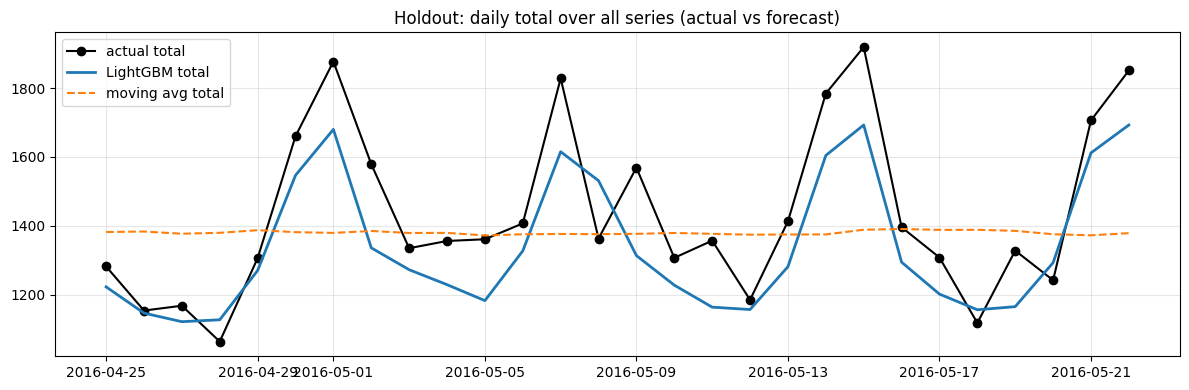

Aggregate daily-total WAPE: LightGBM=0.0845 | MA28=0.1314
Total-demand bias (LightGBM): -6.9%


In [10]:
daily = H_E.groupby("date")[["y", "lgbm_final", "moving_avg_28"]].sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily["y"], "o-", color="black", label="actual total")
ax.plot(daily.index, daily["lgbm_final"], lw=2, label="LightGBM total")
ax.plot(daily.index, daily["moving_avg_28"], lw=1.5, ls="--", label="moving avg total")
ax.set_title("Holdout: daily total over all series (actual vs forecast)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Aggregate daily-total WAPE: LightGBM={wape(daily['y'], daily['lgbm_final']):.4f} | MA28={wape(daily['y'], daily['moving_avg_28']):.4f}")
print(f"Total-demand bias (LightGBM): {(daily['lgbm_final'].sum()/daily['y'].sum()-1)*100:+.1f}%")

---
## 8. Logging the run and summarising

**Append-only log.** Each run adds one line to `holdout_runs.jsonl` containing the time, the model hash and the key numbers. The first line is the official result. If the notebook is run again (for example after an error) the run number increases, which makes it transparent how often the holdout was looked at.

**Saved predictions** (`preds_holdout_h28.parquet`) are used by the inventory simulator (Notebook 6).

The last cell composes a one-sentence summary from the measured numbers, together with its caveats: one state (California), about 3.3% of the M5 series, no test on new items, and daily item-store WAPE values around 0.7–0.8 being normal for zero-heavy data.

In [11]:
log_path = OUT / "holdout_runs.jsonl"
n_prev = sum(1 for _ in open(log_path)) if log_path.exists() else 0
lg = hold_tbl.loc["lgbm_final"]; ma = hold_tbl.loc["moving_avg_28"]
entry = {"timestamp_utc": dt.datetime.now(dt.timezone.utc).replace(tzinfo=None).isoformat(timespec="seconds"), "run_number": n_prev + 1,
         "model_sha256": MODEL_SHA, "config_sha256": MCFG_SHA, "holdout": f"{HOLD_START.date()}..{HOLD_END.date()}",
         "rows": int(len(H_E)), "series": int(H_E["id"].nunique()),
         "WAPE_lgbm": round(float(lg["WAPE"]), 5), "WAPE_ma28": round(float(ma["WAPE"]), 5),
         "improvement_%": round(float(lg["vs_MA28_%"]), 3)}
with open(log_path, "a") as fh:
    fh.write(json.dumps(entry) + "\n")
print(f"Run logged. This is run #{n_prev + 1}.", "(OFFICIAL RESULT)" if n_prev == 0 else f"-> The OFFICIAL result is run #1 (the first line of the log). Do not report this run as official.")

keep_cols = ["id", "date", "vol_tier", "demand_class", "eligible", "y", "naive_lag28", "moving_avg_28", "same_weekday_mean", "croston_sba", "lgbm_final"]
hold_all[keep_cols].rename(columns={"y": "sales"}).to_parquet(OUT / "preds_holdout_h28.parquet", index=False)
print("Saved: preds_holdout_h28.parquet", "| rows:", len(hold_all))

Run logged. This is run #1. (OFFICIAL RESULT)
Saved: preds_holdout_h28.parquet | rows: 27972


In [12]:
n_ser = int(H_E["id"].nunique())
b = boot["daily"]; b7 = boot["7d_sum"]
sentence = (
    f"On a held-out 28-day period ({HOLD_START.date()} to {HOLD_END.date()}) that was never used for feature selection or model selection, "
    f"a LightGBM (Tweedie) demand model reached a WAPE of {b['WAPE']:.3f} versus {b['base_WAPE']:.3f} for a 28-day moving-average baseline "
    f"({b['improvement_%']:.1f}% lower, 95% bootstrap CI {b['improvement_CI'][0]:+.1f}% to {b['improvement_CI'][1]:+.1f}%) across {n_ser} "
    f"California item-store series from the M5 dataset (~{n_ser / FULL_M5_SERIES * 100:.1f}% of M5 series); "
    f"on 7-day demand totals the WAPE was {b7['WAPE']:.3f} vs {b7['base_WAPE']:.3f} ({b7['improvement_%']:.1f}% lower)."
)
print(sentence)
print()
print("Caveats: one state (California) only; not tested on new items; this is daily item-store error (a WAPE of 0.7-0.8 is normal for zero-heavy data).")

On a held-out 28-day period (2016-04-25 to 2016-05-22) that was never used for feature selection or model selection, a LightGBM (Tweedie) demand model reached a WAPE of 0.744 versus 0.789 for a 28-day moving-average baseline (5.7% lower, 95% bootstrap CI +2.9% to +9.1%) across 999 California item-store series from the M5 dataset (~3.3% of M5 series); on 7-day demand totals the WAPE was 0.370 vs 0.416 (11.0% lower).

Caveats: one state (California) only; not tested on new items; this is daily item-store error (a WAPE of 0.7-0.8 is normal for zero-heavy data).


---
## Summary of results (machine-readable)

In [13]:
def rr(x): return round(float(x), 4) if pd.notna(x) else None

summary = {
    "run_number": n_prev + 1, "holdout": f"{HOLD_START.date()}..{HOLD_END.date()}", "origin": str(ORIGIN.date()),
    "model_sha256_prefix": MODEL_SHA[:16], "features_in_model": len(FEATS),
    "leakage_proof": "PASS",
    "rows_eligible": int(len(H_E)), "series_eligible": n_ser, "series_total": int(len(ids)),
    "pct_of_full_M5_series": round(len(ids) / FULL_M5_SERIES * 100, 2),
    "holdout_table": json.loads(hold_tbl.round(4).to_json(orient="index")),
    "fold_vs_holdout": json.loads(cmp.round(4).to_json(orient="index")),
    "bootstrap": {k: {"WAPE": rr(v["WAPE"]), "WAPE_CI": [rr(x) for x in v["WAPE_CI"]], "base_WAPE": rr(v["base_WAPE"]),
                      "improvement_%": rr(v["improvement_%"]), "improvement_CI": [rr(x) for x in v["improvement_CI"]],
                      "P_improvement_gt_0": rr(v["P(improvement>0)"])} for k, v in boot.items()},
    "segments": {by: json.loads(seg[by][["sales_share_%", "WAPE_lgbm", "WAPE_MA28", "improvement_%", "bias_%"]].round(3).to_json(orient="index")) for by in seg},
    "weekday_bias_%": wd["bias_%"].round(2).to_dict(),
    "aggregate_daily_total_WAPE": {"lgbm": rr(wape(daily["y"], daily["lgbm_final"])), "ma28": rr(wape(daily["y"], daily["moving_avg_28"]))},
    "total_demand_bias_%": rr((daily["lgbm_final"].sum() / daily["y"].sum() - 1) * 100),
}
print(json.dumps(summary, indent=2, default=str))

{
  "run_number": 1,
  "holdout": "2016-04-25..2016-05-22",
  "origin": "2016-04-24",
  "model_sha256_prefix": "bdad92a08cba326a",
  "features_in_model": 37,
  "leakage_proof": "PASS",
  "rows_eligible": 27972,
  "series_eligible": 999,
  "series_total": 999,
  "pct_of_full_M5_series": 3.28,
  "holdout_table": {
    "naive_lag28": {
      "WAPE": 0.9238,
      "MAE": 1.3284,
      "bias_%": -4.03,
      "MASE": 1.1349,
      "WAPE_7d_sum": 0.4469,
      "WAPE_28d_sum": 0.2711,
      "vs_MA28_%": -17.0485
    },
    "moving_avg_28": {
      "WAPE": 0.7893,
      "MAE": 1.1349,
      "bias_%": -3.9381,
      "MASE": 0.9778,
      "WAPE_7d_sum": 0.4156,
      "WAPE_28d_sum": 0.3141,
      "vs_MA28_%": 0.0
    },
    "same_weekday_mean": {
      "WAPE": 0.8113,
      "MAE": 1.1667,
      "bias_%": -3.8914,
      "MASE": 1.0075,
      "WAPE_7d_sum": 0.4054,
      "WAPE_28d_sum": 0.3026,
      "vs_MA28_%": -2.7942
    },
    "croston_sba": {
      "WAPE": 0.7909,
      "MAE": 1.1372,
      "